# Aura Detector : quelle est l'aura d'un texte ?

*Projet final, Mastère Dev, Data & IA*

Notre objectif : donner un texte en français à un modèle et qu'il nous dise quelle « aura » il dégage, sur quatre niveaux.

| Classe | Score | Exemple |
|---|---|---|
| Anti-Aura | −100 à −11 | « dab dab, six-seven » |
| Aura Correcte | −10 à +24 | « Le train a eu une heure de retard ce matin. » |
| Forte Aura | +25 à +74 | « Vous avez la mémoire courte et le discours long ! » |
| Aura Divine | +75 à +100 | « L'aura, c'est comme le wifi du voisin : ceux qui en parlent le plus sont ceux qui ne l'ont pas. » |

On juge la **façon de dire les choses**, pas l'opinion. Une moquerie bien tournée a de l'aura, une insulte sèche n'en a pas.

Nous avons comparé trois familles de modèles, de la plus simple à la plus puissante :

1. **un SVM**, du machine learning classique ;
2. **un CNN**, un réseau de neurones que nous entraînons nous-mêmes de zéro ;
3. **CamemBERT**, un modèle de langue déjà entraîné sur du français, que nous adaptons à notre tâche.

Pour chacun, nous avons cherché les meilleurs hyperparamètres, puis nous les avons comparés sur le même test.

**Pour utiliser le notebook**, il suffit de changer ce qu'on veut dans la cellule de paramètres (partie 1) et de tout relancer.

## 1. Paramètres

Nous avons regroupé tous les réglages dans une seule cellule : les fichiers de données, les valeurs testées pour chaque modèle et les phrases de démo. Le reste du notebook n'a aucune valeur écrite en dur. Pour tester une idée, on change une ligne ici et on relance tout.

In [1]:
# ===================== DONNÉES =====================
TRAIN_FICHIERS = [
    "data/train_synthetique.csv",     # 6 991 textes générés (brainrot, SMS, poésie, politique…)
    "data/grok_textes.csv",           # 105 textes écrits par une autre IA
    "data/paires_contrastees.csv",    # 902 textes : même sujet, aura opposée
    "data/train_registres.csv",       # 1 206 textes dans le style du test (Assemblée, théâtre, maximes…)
    "data/train_battle.csv",          # 371 textes de battle rap originaux
    "data/train_joutes_reelles.csv",  # 97 vraies répliques du domaine public (Cyrano, Molière…)
]
VALIDATION = "data/val_domaine.csv"   # sert à choisir les hyperparamètres (jamais le test)
TEST = "data/test_reel.csv"           # 330 vrais textes, uniquement pour la comparaison finale
GRAINE = 42

# ===================== 1) SVM : grille testée en entier =====================
SVM_GRILLE = {
    "C": [0.1, 0.3, 1, 3],                         # inverse de la régularisation
    "ngram_mots": [(1, 1), (1, 2)],                # mots seuls, ou mots + paires de mots
    "ngram_caracteres": [(2, 4), (2, 5), (3, 6)],  # morceaux de lettres
    "class_weight": [None, "balanced"],            # « balanced » = plus de poids aux classes rares
}

# ===================== 2) CNN : recherche aléatoire =====================
CNN_ESPACE = {
    "embedding": [64, 128, 200],                          # taille des vecteurs de mots
    "n_filtres": [50, 100, 200],                          # filtres par largeur
    "largeurs": [[2, 3, 4], [1, 2, 3], [2, 3, 4, 5], [3, 4, 5]],   # largeur des filtres, en mots
    "dropout": [0.3, 0.5],
    "lr": [5e-4, 1e-3, 2e-3],
    "batch": [32, 64],
}
CNN_N_ESSAIS = 20            # nombre de combinaisons tirées au hasard
CNN_FIXE = dict(longueur_max=100, epochs_max=15, patience=3, min_freq=2)

# ===================== 3) CamemBERT =====================
ENTRAINER_CAMEMBERT = False   # True = relance un entraînement (≈ 8 min sur GPU) avec les réglages ci-dessous
CAMEMBERT_MODELE = "almanach/camembert-base"   # ou "almanach/camembert-large"
CAMEMBERT_MODE = "regression"                   # "regression" ou "classification"
CAMEMBERT_LR = 3e-5
CAMEMBERT_GRAINE = 42

# ===================== DÉMO =====================
PHRASES_DEMO = [
    "Je me suis chié dessus",
    "La bière c'est comme ma femme, brune et amer",
    "fort en chocolat",
    "dab dab, six-seven",
    "un accident de train a eu lieu en espagne ce samedi,",
    "En imposer pour ne pas avoir à imposer, voilà en quoi consiste le charisme.",
    "Loin des yeux, loin du cœur",
]

## 2. Chargement des données

Nous utilisons trois jeux de données, chacun avec un rôle précis :

- **le train**, pour apprendre ;
- **la validation**, pour choisir les hyperparamètres ;
- **le test** (330 vrais textes), qu'on ne regarde qu'**une seule fois**, à la toute fin, pour comparer les modèles.

Si on choisissait nos réglages en regardant le test, on finirait par « tricher » sans le vouloir, et le score final serait trop optimiste. Par sécurité, on retire aussi du train tout texte qui apparaîtrait dans la validation ou le test.

In [2]:
import os, sys, time, json, random, itertools, subprocess, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "scripts")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from sklearn.metrics import cohen_kappa_score, f1_score, accuracy_score, confusion_matrix, recall_score

CLASSES = ["Anti-Aura", "Aura Correcte", "Forte Aura", "Aura Divine"]
COURT = ["Anti", "Corr", "Fort", "Divi"]
random.seed(GRAINE); np.random.seed(GRAINE); torch.manual_seed(GRAINE)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def charger(fichiers):
    df = pd.concat([pd.read_csv(f, encoding="utf-8-sig") for f in fichiers], ignore_index=True)
    df = df[df["classe"].isin(CLASSES)].dropna(subset=["texte"])
    df["y"] = df["classe"].map(CLASSES.index)
    return df.reset_index(drop=True)

train, val, test = charger(TRAIN_FICHIERS), charger([VALIDATION]), charger([TEST])
train = train[~train["texte"].isin(set(test["texte"]) | set(val["texte"]))].reset_index(drop=True)
print(f"train : {len(train)} textes | validation : {len(val)} | test : {len(test)} | calcul sur : {DEVICE}")

train : 9671 textes | validation : 240 | test : 330 | calcul sur : cuda


## 3. Analyse des données

Avant de choisir un modèle, nous avons regardé à quoi ressemblent nos données. On commence par la répartition des classes.

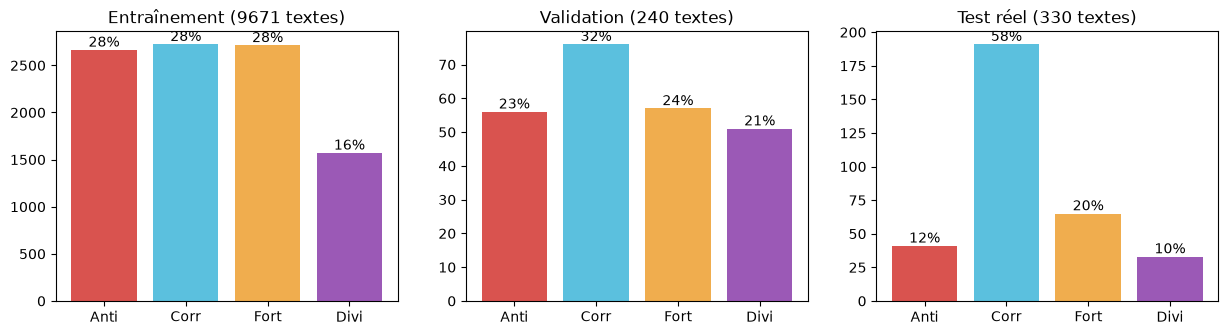

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, (nom, df) in zip(ax, [("Entraînement", train), ("Validation", val), ("Test réel", test)]):
    n = df["classe"].value_counts().reindex(CLASSES)
    a.bar(COURT, n, color=["#d9534f", "#5bc0de", "#f0ad4e", "#9b59b6"])
    for i, v in enumerate(n): a.text(i, v, f"{v / n.sum():.0%}", ha="center", va="bottom")
    a.set_title(f"{nom} ({len(df)} textes)")
plt.show()

Premier constat : notre train est équilibré, mais pas le test, qui contient **58 % d'« Aura Correcte »**. Un modèle qui répondrait toujours « Correcte » aurait donc déjà 58 % de bonnes réponses sans rien comprendre. C'est pour ça que nous ne jugeons pas nos modèles sur le pourcentage de bonnes réponses (voir la partie 4).

In [4]:
def profil(df):
    t = df["texte"]
    return {"mots par texte": t.str.split().str.len().mean(), "% avec « ! »": t.str.contains("!").mean() * 100,
            "% avec emoji": t.str.contains(r"[\U0001F300-\U0001FAFF]").mean() * 100}
display(pd.DataFrame({"train synthétique": profil(charger(["data/train_synthetique.csv"])), "test réel": profil(test)}).round(1))
print("Types de texte du test :", test["type"].value_counts().head(6).to_dict())

,train synthétique,test réel
mots par texte,26.4,11.4
% avec « ! »,4.9,31.5
% avec emoji,11.1,0.0


Types de texte du test : {'discours': 101, 'interjection': 65, 'théâtre': 35, 'poésie': 22, 'question': 20, 'réponse': 18}


Deuxième constat, le plus important du projet : **nos données d'entraînement ne ressemblent pas au test.** Nos premiers textes étaient générés (brainrot, SMS, bios), avec des emojis et des phrases plutôt longues. Le test, lui, contient de vrais textes courts : séances de l'Assemblée nationale, théâtre, poésie, discours. Il n'y a aucun emoji, et beaucoup de points d'exclamation.

Un modèle apprend le style qu'on lui montre. Pour réduire cet écart, nous avons écrit des données supplémentaires dans le style du test (`train_registres`, `train_battle`, `train_joutes_reelles`). On peut les activer ou non dans les paramètres.

### 3 bis. D'où vient la classe ? La formule R-S-O-B-P

Pour bien comprendre ce que nos modèles doivent apprendre, il faut d'abord savoir **comment une étiquette est fabriquée**. Chaque texte reçoit 5 notes, de −100 à +100 :

| Lettre | Critère | La question qu'on se pose | Poids |
|---|---|---|---|
| **R** | Rizz | La phrase a-t-elle de l'aplomb ? Fait-elle mouche ? | 6/18 ≈ 33 % |
| **S** | Statut | Celui qui parle se met-il en position de force ? | 4/18 ≈ 22 % |
| **O** | Originalité | C'est inattendu, ou c'est un cliché ? | 3/18 ≈ 17 % |
| **B** | Beauté / style | Est-ce bien écrit ? | 3/18 ≈ 17 % |
| **P** | Poésie / forme | Y a-t-il du rythme, des rimes, des jeux de sons ? | 2/18 ≈ 11 % |

**Étape 1 : on combine les 5 notes en un score** (une moyenne pondérée) :

$$
\text{Score} \;=\; \frac{6\,R \;+\; 4\,S \;+\; 3\,O \;+\; 3\,B \;+\; 2\,P}{18}
$$

Les poids font 18/18 = 1 au total, donc le score reste lui aussi entre −100 et +100. Ces poids sont donnés par le cahier des charges. Nous les trouvons logiques : l'aura, c'est d'abord **l'impact** (R) et **la posture** (S), qui font plus de la moitié du score. La forme (P) compte, mais des rimes seules ne donnent pas de l'aura.

**Étape 2 : on découpe le score en 4 classes** :

$$
\text{classe} \;=\;
\begin{cases}
\text{Anti-Aura} & \text{si } \text{Score} \le -11 \\
\text{Aura Correcte} & \text{si } -10 \le \text{Score} \le 24 \\
\text{Forte Aura} & \text{si } 25 \le \text{Score} \le 74 \\
\text{Aura Divine} & \text{si } \text{Score} \ge 75
\end{cases}
$$

En résumé, **la classe n'est qu'un score « arrondi » en 4 cases.** Les classes ont donc un ordre, et c'est une idée que nous réutilisons pour choisir notre métrique (partie 4) et dans CamemBERT (partie 7).

In [5]:
POIDS = {"R": 6/18, "S": 4/18, "O": 3/18, "B": 3/18, "P": 2/18}
SEUILS = [-10.5, 24.5, 74.5]          # frontières entre Anti | Correcte | Forte | Divine

def score_aura(R, S, O, B, P):
    return POIDS["R"]*R + POIDS["S"]*S + POIDS["O"]*O + POIDS["B"]*B + POIDS["P"]*P

def classe_aura(score):
    return CLASSES[int(np.digitize(score, SEUILS))]

# Exemple : même situation, deux façons de réagir (une paire de train_registres)
exemples = {
    "« C'est honteux ! Honteux ! »": dict(R=-30, S=-15, O=-40, B=-25, P=-20),
    "« Honteux ? Non : prévisible, ce qui est pire. »": dict(R=40, S=40, O=45, B=40, P=35),
}
for texte, n in exemples.items():
    s = score_aura(**n)
    detail = " + ".join(f"{POIDS[k]:.3f}×{v}" for k, v in n.items())
    print(f"{texte}\n   score = {detail} = {s:.1f}  →  {classe_aura(s)}\n")

« C'est honteux ! Honteux ! »
   score = 0.333×-30 + 0.222×-15 + 0.167×-40 + 0.167×-25 + 0.111×-20 = -26.4  →  Anti-Aura

« Honteux ? Non : prévisible, ce qui est pire. »
   score = 0.333×40 + 0.222×40 + 0.167×45 + 0.167×40 + 0.111×35 = 40.3  →  Forte Aura



Ces deux textes réagissent à la même situation. Le premier crie, mais n'a ni répartie ni originalité : toutes ses notes sont négatives, il tombe en Anti-Aura. Le second répond par une pique calme et inattendue : toutes ses notes passent dans le positif, il monte en Forte Aura. **C'est exactement cette différence que nos modèles doivent apprendre à voir.**

Ci-dessous, nous regardons ce que chaque critère apporte au score, puis nous vérifions que la formule colle bien à nos données.

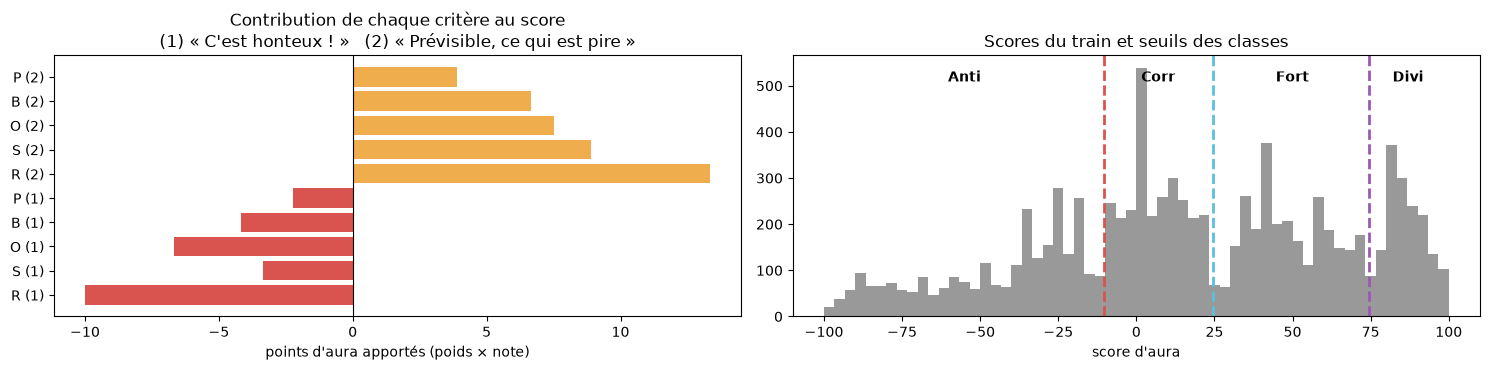

1577 textes du train ont les 5 notes R, S, O, B, P.
écart max entre la formule et le score annoté : 0.50 (arrondi à l'entier)
classe retrouvée par les seuils : 100%


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))

# (a) contribution de chaque critère au score, pour les deux exemples
lettres = list(POIDS)
for i, (texte, n) in enumerate(exemples.items()):
    contrib = [POIDS[k] * n[k] for k in lettres]
    ax[0].barh([f"{k} ({i+1})" for k in lettres], contrib, color="#d9534f" if i == 0 else "#f0ad4e")
ax[0].axvline(0, color="k", lw=0.8)
ax[0].set_title("Contribution de chaque critère au score\n(1) « C'est honteux ! »   (2) « Prévisible, ce qui est pire »")
ax[0].set_xlabel("points d'aura apportés (poids × note)")

# (b) les scores du train, découpés par les seuils
avec_notes = train.dropna(subset=lettres) if all(k in train for k in lettres) else train.iloc[0:0]
ax[1].hist(train["score"], bins=60, color="#999")
for s, c in zip(SEUILS, ["#d9534f", "#5bc0de", "#9b59b6"]): ax[1].axvline(s, color=c, ls="--", lw=2)
for x, nom in zip([-55, 7, 50, 87], COURT): ax[1].text(x, ax[1].get_ylim()[1] * 0.9, nom, ha="center", fontweight="bold")
ax[1].set_title("Scores du train et seuils des classes"); ax[1].set_xlabel("score d'aura")
plt.tight_layout(); plt.show()

# vérification : la formule redonne-t-elle bien le score et la classe annotés ?
if len(avec_notes):
    recalc = score_aura(*(avec_notes[k] for k in lettres))
    print(f"{len(avec_notes)} textes du train ont les 5 notes R, S, O, B, P.")
    print(f"écart max entre la formule et le score annoté : {(recalc - avec_notes['score']).abs().max():.2f} (arrondi à l'entier)")
    print(f"classe retrouvée par les seuils : {(recalc.map(classe_aura) == avec_notes['classe']).mean():.0%}")

Sur les 1 577 textes du train qui ont le détail des 5 notes, la formule redonne le score à l'arrondi près, et les seuils redonnent la bonne classe dans 100 % des cas. Nos étiquettes sont donc cohérentes.

**Et les modèles ?** Ils ne voient **jamais** ces 5 notes, seulement le texte. Leur travail est d'imiter l'annotateur :

- le SVM et le CNN prédisent directement la classe ;
- CamemBERT, dans notre version, prédit le **score** (étape 1), puis on applique les seuils (étape 2). Il suit donc la même démarche que l'annotateur.

Une conséquence : un texte noté 24 est « Correcte » et un texte noté 25 est « Forte ». Près d'un seuil, une toute petite erreur fait changer de classe. Ces erreurs d'une case sont inévitables, et c'est pour ça que nous avons choisi une métrique qui les pénalise peu.

## 4. Comment on mesure les résultats

Comme nos classes ont un ordre (Anti < Correcte < Forte < Divine), toutes les erreurs ne se valent pas. Prendre un texte Anti pour du Divine est bien plus grave que de confondre Forte et Divine.

Nous avons donc choisi le **kappa quadratique** comme mesure principale :

- **0** correspond à un modèle qui ne fait pas mieux que le hasard, par exemple celui qui répond toujours « Correcte » ;
- **1** correspond à un modèle parfait ;
- l'erreur est mise au carré, donc se tromper de 3 cases coûte 9 fois plus que de se tromper d'une seule.

C'est aussi ce kappa, calculé sur la validation, qui nous sert à choisir les hyperparamètres de chaque modèle. À côté, nous regardons le F1-macro (qui donne autant d'importance à la petite classe Divine qu'aux autres), le rappel de chaque classe et la matrice de confusion.

In [7]:
kappa = lambda y, p: cohen_kappa_score(y, p, weights="quadratic")
RESULTATS, PREDICTIONS = {}, {}

def evaluer(nom, y_pred, temps_entrainement=None, n_parametres=None):
    y = test["y"].values; y_pred = np.asarray(y_pred); PREDICTIONS[nom] = y_pred
    rappel = recall_score(y, y_pred, labels=range(4), average=None, zero_division=0)
    RESULTATS[nom] = {"kappa": kappa(y, y_pred), "F1-macro": f1_score(y, y_pred, average="macro"),
                      "exactitude": accuracy_score(y, y_pred), "à ±1 classe": np.mean(abs(y - y_pred) <= 1),
                      **{f"rappel {c}": r for c, r in zip(COURT, rappel)},
                      "entraînement (s)": temps_entrainement, "paramètres": n_parametres}
    print(nom, "→ kappa test", round(RESULTATS[nom]["kappa"], 3))

evaluer("Toujours « Aura Correcte »", np.ones(len(test), dtype=int))

Toujours « Aura Correcte » → kappa test 0.0


## 5. Modèle 1 : SVM (machine learning)

**Comment ça marche.** On transforme chaque texte en une longue liste de nombres (TF-IDF). Chaque nombre indique si un mot, une paire de mots ou un petit morceau de lettres est présent, et s'il est rare ou courant. Le SVM cherche ensuite la « frontière » qui sépare le mieux les classes dans cet espace.

**Pourquoi nous l'avons choisi.** C'est la référence classique pour classer du texte. Il est rapide (quelques secondes), facile à expliquer, et les morceaux de lettres l'aident avec les fautes et l'argot. Il nous sert de point de départ : si un modèle plus compliqué ne fait pas mieux, il ne vaut pas la peine.

**Notre recherche d'hyperparamètres.** Le SVM est rapide, donc nous avons pu tester **toutes** les combinaisons de la grille (48 au total). Chaque combinaison est entraînée sur le train, notée sur la validation, et nous gardons la meilleure.

In [8]:
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.metrics import make_scorer

svm = Pipeline([
    ("tfidf", FeatureUnion([("mots", TfidfVectorizer(analyzer="word", min_df=2, sublinear_tf=True)),
                            ("caracteres", TfidfVectorizer(analyzer="char_wb", min_df=2, sublinear_tf=True))])),
    ("svm", LinearSVC(max_iter=5000))])
grille = {"svm__C": SVM_GRILLE["C"], "tfidf__mots__ngram_range": SVM_GRILLE["ngram_mots"],
          "tfidf__caracteres__ngram_range": SVM_GRILLE["ngram_caracteres"], "svm__class_weight": SVM_GRILLE["class_weight"]}

# train et validation mis bout à bout ; PredefinedSplit indique « entraîne sur le train (-1), évalue sur la validation (0) »
X_tv = pd.concat([train["texte"], val["texte"]]); y_tv = np.concatenate([train["y"], val["y"]])
decoupe = PredefinedSplit([-1] * len(train) + [0] * len(val))
recherche = GridSearchCV(svm, grille, scoring=make_scorer(kappa), cv=decoupe, n_jobs=-1, refit=False)
t0 = time.time(); recherche.fit(X_tv, y_tv)
print(f"{len(recherche.cv_results_['params'])} combinaisons testées en {time.time() - t0:.0f} s")
tableau_svm = pd.DataFrame(recherche.cv_results_["params"]).assign(kappa_validation=recherche.cv_results_["mean_test_score"])
tableau_svm.columns = [c.split("__")[-1] for c in tableau_svm.columns]
display(tableau_svm.sort_values("kappa_validation", ascending=False).head(10).round(3))

48 combinaisons testées en 49 s


,C,class_weight,ngram_range,ngram_range,kappa_validation
17,0.3,NaN,"(3, 6)","(1, 2)",0.743
30,1.0,balanced,"(2, 4)","(1, 1)",0.738
11,0.1,balanced,"(3, 6)","(1, 2)",0.733
24,1.0,NaN,"(2, 4)","(1, 1)",0.733
0,0.1,NaN,"(2, 4)","(1, 1)",0.733
23,0.3,balanced,"(3, 6)","(1, 2)",0.732
19,0.3,balanced,"(2, 4)","(1, 2)",0.730
6,0.1,balanced,"(2, 4)","(1, 1)",0.725
8,0.1,balanced,"(2, 5)","(1, 1)",0.725
1,0.1,NaN,"(2, 4)","(1, 2)",0.723


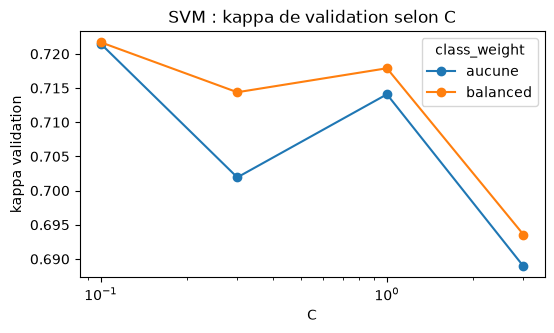

In [9]:
# Effet de C et de la pondération des classes (moyenne sur les autres réglages)
pivot = tableau_svm.assign(class_weight=tableau_svm["class_weight"].fillna("aucune")).pivot_table(index="C", columns="class_weight", values="kappa_validation")
pivot.plot(marker="o", figsize=(6, 3.2), title="SVM : kappa de validation selon C"); plt.ylabel("kappa validation"); plt.xscale("log"); plt.show()

Le paramètre C règle la « sévérité » du modèle. Un petit C donne un modèle prudent, qui généralise mais peut rester trop simple. Un grand C donne un modèle qui colle au train, au risque d'apprendre par cœur.

**Ce que nous avons retenu :** C = 0,3, sans pondération des classes, avec les mots seuls et les paires de mots, et des morceaux de 3 à 6 lettres (kappa de validation 0,743). On remarque que les 10 meilleures combinaisons sont toutes entre 0,72 et 0,74 : pour le SVM, les réglages changent peu de chose.

In [10]:
from sklearn.calibration import CalibratedClassifierCV
import joblib

meilleurs = recherche.best_params_
print("Meilleurs hyperparamètres :", meilleurs, "| kappa validation", round(recherche.best_score_, 3))
svm.set_params(**meilleurs)
t0 = time.time(); svm.fit(train["texte"], train["y"]); t_svm = time.time() - t0
evaluer("1. SVM", svm.predict(test["texte"]), t_svm, int(svm["svm"].coef_.size + svm["svm"].intercept_.size))

# Pour la WebApp il faut une probabilité : on « calibre » le SVM (il n'en donne pas nativement)
svm_proba = Pipeline([("tfidf", svm["tfidf"]), ("svm", CalibratedClassifierCV(LinearSVC(C=meilleurs["svm__C"], class_weight=meilleurs["svm__class_weight"], max_iter=5000), cv=3))])
svm_proba.fit(train["texte"], train["y"])
os.makedirs("models", exist_ok=True); joblib.dump(svm_proba, "models/svm.joblib")

Meilleurs hyperparamètres : {'svm__C': 0.3, 'svm__class_weight': None, 'tfidf__caracteres__ngram_range': (3, 6), 'tfidf__mots__ngram_range': (1, 2)} | kappa validation 0.743


1. SVM → kappa test 0.147


['models/svm.joblib']

## 6. Modèle 2 : CNN (réseau de neurones convolutif)

**Comment ça marche.** Chaque mot devient un petit vecteur, que le réseau apprend lui-même. Ensuite, des **filtres** glissent sur la phrase, 1, 2 ou 3 mots à la fois, comme une loupe qui se déplace. Chaque filtre apprend à reconnaître un motif, par exemple « c'est vous ! » ou une tournure de proverbe. Pour chaque filtre, on garde l'endroit de la phrase où le motif est le plus fort, et une dernière couche en déduit les 4 classes. Rien n'est pré-entraîné : tout est appris à partir de nos textes.

**Pourquoi un CNN plutôt qu'un RNN (LSTM) ?** Nous avons hésité entre les deux, et le CNN nous a paru plus adapté :

- **Nos textes sont courts** (une réplique, une punchline) et l'aura tient souvent dans **quelques mots** : une chute, une répétition, une formule. C'est exactement ce que détectent les filtres d'un CNN. Un RNN lit le texte mot par mot en gardant une mémoire, ce qui sert surtout pour des textes longs.
- **Il est beaucoup plus rapide** : il traite tous les mots en même temps, alors qu'un RNN les lit un par un. Un entraînement prend environ 10 secondes, ce qui nous a permis de tester 20 configurations.
- **Il a moins de paramètres**, donc il apprend moins par cœur sur un petit jeu de données comme le nôtre.

Sa limite : il ne voit pas les constructions qui s'étalent sur toute la phrase. Pour ça, CamemBERT est bien meilleur.

Voici le code du modèle :

In [11]:
import inspect, cnn
print(inspect.getsource(cnn.TextCNN))

class TextCNN(nn.Module):
    def __init__(self, n_mots, embedding=128, n_filtres=100, largeurs=(2, 3, 4), dropout=0.5, n_classes=4):
        super().__init__()
        self.emb = nn.Embedding(n_mots, embedding, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(embedding, n_filtres, k) for k in largeurs])
        self.drop = nn.Dropout(dropout)
        self.sortie = nn.Linear(n_filtres * len(largeurs), n_classes)

    def forward(self, x):
        e = self.emb(x).transpose(1, 2)                                   # (batch, embedding, mots)
        h = [torch.relu(conv(e)).max(dim=2).values for conv in self.convs]  # max-pooling global par filtre
        return self.sortie(self.drop(torch.cat(h, dim=1)))



**Notre recherche d'hyperparamètres.** Notre grille contient 432 combinaisons, trop pour toutes les essayer. Nous avons donc fait une **recherche aléatoire** : on tire 20 combinaisons au hasard et on garde la meilleure. Des études ont montré que cette méthode trouve presque aussi bien qu'une recherche complète pour beaucoup moins de calcul.

Chaque entraînement s'arrête tout seul quand le kappa de validation ne progresse plus pendant 3 epochs (early stopping). Cela évite le surapprentissage et fait gagner du temps.

In [12]:
toutes = [dict(zip(CNN_ESPACE, v)) for v in itertools.product(*CNN_ESPACE.values())]
essais = random.Random(GRAINE).sample(toutes, min(CNN_N_ESSAIS, len(toutes)))
print(f"{len(toutes)} combinaisons possibles, {len(essais)} tirées au hasard")
resultats_cnn, meilleur_cnn, t0 = [], None, time.time()
for i, cfg in enumerate(essais, 1):
    r = cnn.entrainer(train["texte"].tolist(), train["y"].values, val["texte"].tolist(), val["y"].values,
                      {**cfg, **CNN_FIXE}, DEVICE, GRAINE)
    resultats_cnn.append({**{k: str(v) if isinstance(v, list) else v for k, v in cfg.items()},
                          "kappa_validation": r["val_kappa"], "meilleure_epoch": r["best_epoch"], "secondes": r["temps_s"]})
    if meilleur_cnn is None or r["val_kappa"] > meilleur_cnn["val_kappa"]: meilleur_cnn = r
    print(f"essai {i:2d} : kappa validation {r['val_kappa']:.3f}  {cfg}")
print(f"recherche terminée en {time.time() - t0:.0f} s")
tableau_cnn = pd.DataFrame(resultats_cnn).sort_values("kappa_validation", ascending=False)
display(tableau_cnn.head(10).round(3))

432 combinaisons possibles, 20 tirées au hasard


essai  1 : kappa validation 0.700  {'embedding': 200, 'n_filtres': 50, 'largeurs': [3, 4, 5], 'dropout': 0.3, 'lr': 0.001, 'batch': 64}


essai  2 : kappa validation 0.687  {'embedding': 64, 'n_filtres': 100, 'largeurs': [2, 3, 4], 'dropout': 0.5, 'lr': 0.001, 'batch': 64}


essai  3 : kappa validation 0.705  {'embedding': 64, 'n_filtres': 50, 'largeurs': [1, 2, 3], 'dropout': 0.3, 'lr': 0.0005, 'batch': 32}


essai  4 : kappa validation 0.694  {'embedding': 200, 'n_filtres': 100, 'largeurs': [3, 4, 5], 'dropout': 0.5, 'lr': 0.0005, 'batch': 64}


essai  5 : kappa validation 0.740  {'embedding': 64, 'n_filtres': 200, 'largeurs': [3, 4, 5], 'dropout': 0.5, 'lr': 0.001, 'batch': 32}


... (12 outputs left out)

essai 18 : kappa validation 0.704  {'embedding': 64, 'n_filtres': 50, 'largeurs': [3, 4, 5], 'dropout': 0.5, 'lr': 0.002, 'batch': 64}


essai 19 : kappa validation 0.714  {'embedding': 64, 'n_filtres': 200, 'largeurs': [1, 2, 3], 'dropout': 0.3, 'lr': 0.001, 'batch': 64}


essai 20 : kappa validation 0.723  {'embedding': 64, 'n_filtres': 200, 'largeurs': [1, 2, 3], 'dropout': 0.5, 'lr': 0.002, 'batch': 64}
recherche terminée en 206 s


,embedding,n_filtres,largeurs,dropout,lr,batch,kappa_validation,meilleure_epoch,secondes
16,64,50,"[1, 2, 3]",0.3,0.001,64,0.756,15,9.936
12,64,50,"[3, 4, 5]",0.5,0.001,32,0.742,10,16.766
4,64,200,"[3, 4, 5]",0.5,0.001,32,0.740,9,13.948
13,200,50,"[1, 2, 3]",0.3,0.001,32,0.738,7,12.236
7,64,100,"[1, 2, 3]",0.5,0.002,64,0.738,4,3.963
6,64,200,"[1, 2, 3]",0.5,0.000,32,0.736,8,12.132
15,64,50,"[1, 2, 3]",0.3,0.002,32,0.733,5,10.774
19,64,200,"[1, 2, 3]",0.5,0.002,64,0.723,5,5.174
10,200,100,"[2, 3, 4]",0.5,0.002,32,0.723,4,7.887
18,64,200,"[1, 2, 3]",0.3,0.001,64,0.714,5,5.408


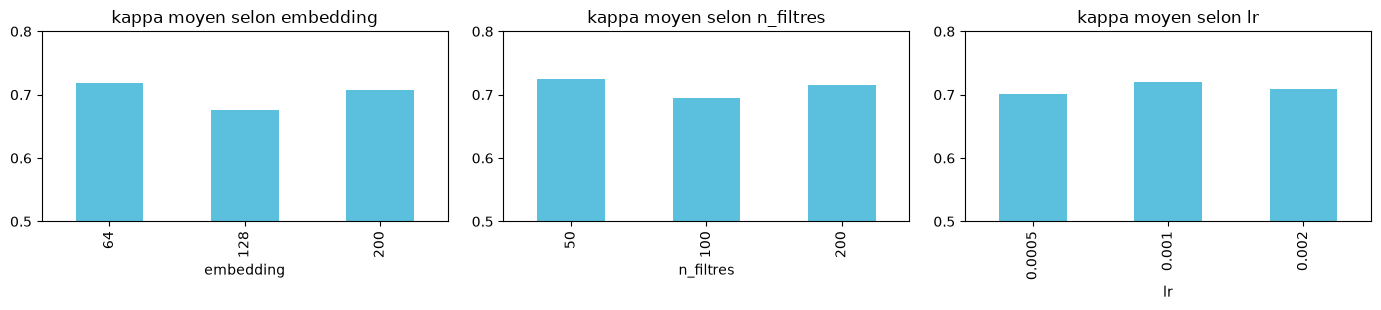

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
for a, h in zip(ax, ["embedding", "n_filtres", "lr"]):
    tableau_cnn.groupby(h)["kappa_validation"].mean().plot.bar(ax=a, color="#5bc0de"); a.set_title(f"kappa moyen selon {h}"); a.set_ylim(0.5, 0.8)
plt.tight_layout(); plt.show()

Meilleure configuration : {'embedding': 64, 'n_filtres': 50, 'largeurs': [1, 2, 3], 'dropout': 0.3, 'lr': 0.001, 'batch': 64, 'longueur_max': 100, 'epochs_max': 15, 'patience': 3, 'min_freq': 2}


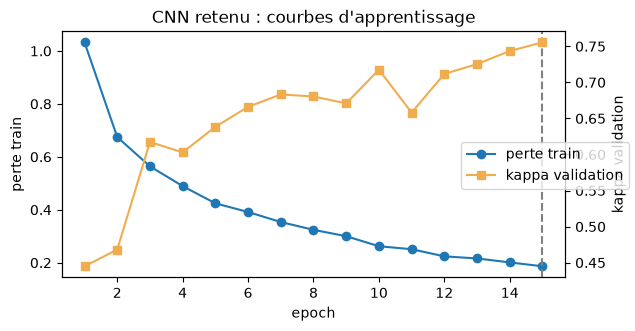

2. CNN → kappa test 0.169


In [14]:
print("Meilleure configuration :", meilleur_cnn["cfg"])
h = meilleur_cnn["hist"]
fig, ax1 = plt.subplots(figsize=(6.5, 3.2)); ax2 = ax1.twinx()
ax1.plot(range(1, len(h["train"]) + 1), h["train"], "o-", label="perte train"); ax2.plot(range(1, len(h["val_kappa"]) + 1), h["val_kappa"], "s-", c="#f0ad4e", label="kappa validation")
ax1.axvline(meilleur_cnn["best_epoch"], ls="--", c="gray"); ax1.set_xlabel("epoch"); ax1.set_ylabel("perte train"); ax2.set_ylabel("kappa validation")
fig.legend(loc="center right"); plt.title("CNN retenu : courbes d'apprentissage"); plt.show()

X_test = cnn.encoder(test["texte"], meilleur_cnn["vocab"], meilleur_cnn["cfg"]["longueur_max"])
evaluer("2. CNN", cnn.predire_classes(meilleur_cnn["modele"], X_test, DEVICE), meilleur_cnn["temps_s"], meilleur_cnn["n_parametres"])
cnn.sauver(meilleur_cnn, "models/cnn")

**Ce que nous avons observé :**

- Les essais vont de 0,67 à 0,76 de kappa de validation : pour le CNN, les réglages comptent plus que pour le SVM.
- **Les petits réseaux gagnent.** Le meilleur a des vecteurs de mots de taille 64 et seulement 50 filtres par largeur. Avec nos quelques milliers de textes, un réseau plus gros a tendance à apprendre par cœur.
- **Les filtres de 1 à 3 mots** marchent le mieux, ce qui confirme que les indices d'aura sont très locaux.

Configuration retenue : embedding 64, 50 filtres de largeur 1, 2 et 3, dropout 0,3, taux d'apprentissage 0,001, batch 64 (kappa de validation 0,756).

Sur la courbe, la perte du train baisse sans arrêt alors que le kappa de validation finit par plafonner : c'est le signe que le modèle commence à mémoriser. Le trait en pointillés marque l'epoch gardée. Ici, la meilleure epoch est la 15e, c'est-à-dire la dernière autorisée. Le modèle aurait donc peut-être gagné un peu en s'entraînant plus longtemps (paramètre `epochs_max`).

## 7. Modèle 3 : CamemBERT (pré-entraîné)

**Comment ça marche.** CamemBERT est un grand modèle (un Transformer) qui a déjà lu 138 Go de textes en français. Il connaît donc la langue, le second degré et les tournures littéraires. Nous l'**adaptons** à notre tâche en continuant son entraînement sur nos textes (c'est le fine-tuning). Il y a deux façons de le faire :

- en **classification** : il choisit directement une des 4 classes ;
- en **régression** : il prédit le score de −100 à +100, puis on applique les seuils de la partie 3 bis. Cette façon respecte l'ordre des classes.

**Pourquoi nous l'avons choisi.** Avec quelques milliers de textes, le SVM et le CNN ne peuvent pas apprendre ce qu'est le français. CamemBERT, lui, le sait déjà : il ne lui reste qu'à apprendre ce qu'est l'aura. C'est l'avantage du pré-entraînement.

**Notre recherche d'hyperparamètres.** Un entraînement prend entre 7 et 30 minutes sur notre GPU. Impossible de tester des dizaines de combinaisons comme pour le SVM : nous avons donc changé **un réglage à la fois**, en choisissant toujours sur la validation :

- le taux d'apprentissage : 2e-5, 3e-5 ou 5e-5 ;
- régression ou classification ;
- en classification, le poids donné aux erreurs sur la classe Divine (×1, ×2 ou ×3), parce que c'est la classe la plus rare ;
- la taille du modèle : base (110 millions de paramètres) ou large (335 millions) ;
- la graine aléatoire, avec 3 essais pour mesurer le rôle du hasard.

Cela fait 11 entraînements, environ 1 h 45 de GPU au total. Ils ont été lancés avec `scripts/train_camembert_v2.py`, et nous rechargeons ici leurs résultats (`results/recherche_camembert/`). Pour gagner de la place, nous n'avons gardé que les poids des modèles qui composent le modèle final. Pour en relancer un, il suffit de mettre `ENTRAINER_CAMEMBERT = True` dans les paramètres.

In [15]:
if ENTRAINER_CAMEMBERT:
    sortie = f"models/p2_notebook_{CAMEMBERT_MODE}_s{CAMEMBERT_GRAINE}"
    subprocess.run([sys.executable, "scripts/train_camembert_v2.py", "--model", CAMEMBERT_MODELE, "--mode", CAMEMBERT_MODE,
                    "--lr", str(CAMEMBERT_LR), "--seed", str(CAMEMBERT_GRAINE), "--out", sortie,
                    *(["--class-weights", "--divine-weight", "3"] if CAMEMBERT_MODE == "classification" else [])], check=True)

# Les résultats de chaque entraînement sont gardés dans results/recherche_camembert/ (un petit fichier par essai).
# Les poids des essais non retenus ont été supprimés pour gagner de la place : seuls ceux du modèle final restent dans models/.
DOSSIER_RECHERCHE = "results/recherche_camembert"
if ENTRAINER_CAMEMBERT:
    import shutil; shutil.copy(f"{sortie}/resultats.json", f"{DOSSIER_RECHERCHE}/{os.path.basename(sortie)}.json")
lignes = []
for fichier in sorted(os.listdir(DOSSIER_RECHERCHE)):
    if fichier.endswith(".json"):
        r = json.load(open(f"{DOSSIER_RECHERCHE}/{fichier}", encoding="utf-8")); a = r["args"]; d = fichier[:-5]
        lignes.append({"run": d, "taille": "large" if "large" in a["model"] else "base", "mode": r["mode"], "lr": a["lr"],
                       "poids Divine": a["divine_weight"] if a.get("class_weights") else "-", "graine": a["seed"],
                       "meilleure epoch": r["best_epoch"], "minutes": r["temps_entrainement_s"] / 60,
                       "kappa_validation": r["val_domaine"]["kappa_quadratique"]})
tableau_bert = pd.DataFrame(lignes).set_index("run").sort_values("kappa_validation", ascending=False)
display(tableau_bert.round(3).assign(lr=tableau_bert["lr"].map("{:.0e}".format)))

,taille,mode,lr,poids Divine,graine,meilleure epoch,minutes,kappa_validation
run,,,,,,,,
p2_cls_w3_s42,base,classification,3e-05,3.0,42,5.0,7.859,0.933
p2_cls_w1_s42,base,classification,3e-05,1.0,42,5.0,7.972,0.931
p2_cls_w3_s43,base,classification,3e-05,3.0,43,4.0,7.919,0.929
p2_reg_s42,base,regression,3e-05,-,42,6.0,9.110,0.927
p2_cls_w2_s42,base,classification,3e-05,2.0,42,4.0,7.866,0.925
p2_reg_s43,base,regression,3e-05,-,43,6.0,7.372,0.925
p2_large_reg_s42,large,regression,2e-05,-,42,4.0,29.584,0.921
p2_reg_lr5e-5_s42,base,regression,5e-05,-,42,4.0,7.029,0.921
p2_cls_w3_s44,base,classification,3e-05,3.0,44,3.0,6.601,0.919


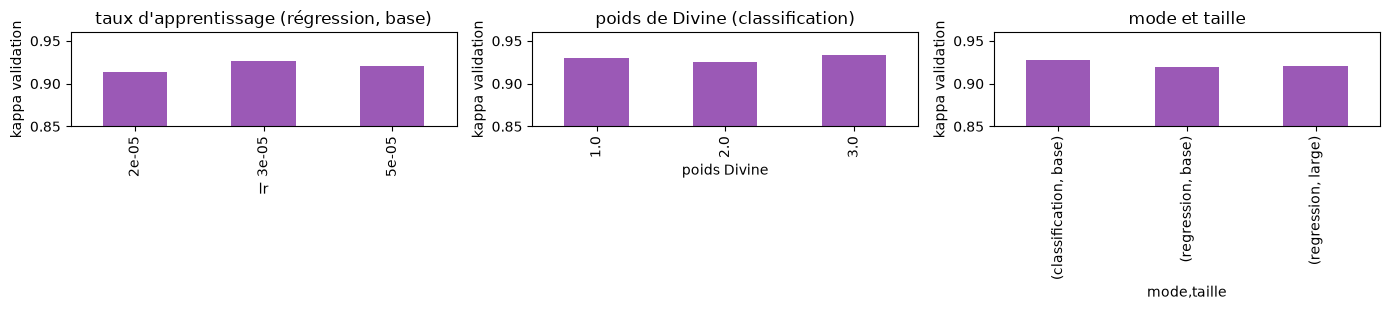

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
reg_base = tableau_bert[(tableau_bert["mode"] == "regression") & (tableau_bert["taille"] == "base") & (tableau_bert["graine"] == 42)]
reg_base.groupby("lr")["kappa_validation"].mean().plot.bar(ax=ax[0], color="#9b59b6", title="taux d'apprentissage (régression, base)")
cls = tableau_bert[(tableau_bert["mode"] == "classification") & (tableau_bert["graine"] == 42)]
cls.groupby("poids Divine")["kappa_validation"].mean().plot.bar(ax=ax[1], color="#9b59b6", title="poids de Divine (classification)")
tableau_bert.groupby(["mode", "taille"])["kappa_validation"].mean().plot.bar(ax=ax[2], color="#9b59b6", title="mode et taille")
for a in ax: a.set_ylim(0.85, 0.96); a.set_ylabel("kappa validation")
plt.tight_layout(); plt.show()

**Ce que nous avons observé :**

- Tous les réglages donnent entre 0,91 et 0,93 sur la validation, bien au-dessus du SVM et du CNN (environ 0,75).
- **Le hasard pèse autant que les réglages.** Avec exactement les mêmes réglages et 3 graines différentes, le kappa varie de 0,910 à 0,927. C'est autant que l'écart entre deux taux d'apprentissage. Nous avons donc gardé les réglages standards (taux d'apprentissage 3e-5) sans sur-interpréter des écarts de 0,01.

Comme aucune variante seule ne se détachait, nous avons préféré **combiner plusieurs modèles** (un ensemble) :

- 60 % pour le camembert-large en régression ;
- 40 % pour trois CamemBERT en classification (poids Divine ×3, trois graines différentes) ;
- puis des seuils réajustés (−12 / 36 / 69).

L'intuition : deux modèles qui ne se trompent pas de la même façon se corrigent l'un l'autre. Sur la validation, cet ensemble monte à **0,949**, mieux que n'importe quel modèle seul. Les poids et les seuils ont été choisis uniquement sur la validation (`scripts/phase2_final.py`).

In [17]:
choix = json.load(open("results/p2_choix.json", encoding="utf-8"))
retenu = choix["candidats"][choix["meilleur"]]
print("Composants :", {k: round(v, 2) for k, v in retenu["composants"].items()}, "| seuils :", retenu["seuils"], "| kappa validation :", round(retenu["val_kappa"], 3))
pred_bert = pd.read_csv("results/predictions_phase2.csv", encoding="utf-8-sig")["prediction"].map(CLASSES.index).values
n_param = sum(json.load(open(f"results/recherche_camembert/{n}.json"))["n_parametres"] for n in retenu["composants"] if n != "tfidf")
t_bert = sum(json.load(open(f"results/recherche_camembert/{n}.json"))["temps_entrainement_s"] for n in retenu["composants"] if n != "tfidf")
evaluer("3. CamemBERT (ensemble)", pred_bert, t_bert, n_param)

Composants : {'p2_large_reg_s42': 0.6, 'p2_cls_w3_s42': 0.13, 'p2_cls_w3_s43': 0.13, 'p2_cls_w3_s44': 0.13} | seuils : [-12, 36, 69.0] | kappa validation : 0.949
3. CamemBERT (ensemble) → kappa test 0.389


## 8. Comparaison des trois modèles

C'est le moment où nous utilisons le test, pour la seule et unique fois : les trois modèles retenus sont évalués sur les mêmes 330 vrais textes.

In [18]:
tab = pd.DataFrame(RESULTATS).T
display(tab.style.format({c: "{:.3f}" for c in ["kappa", "F1-macro"]} | {c: "{:.0%}" for c in tab.columns if "rappel" in c or c in ("exactitude", "à ±1 classe")}
                         | {"entraînement (s)": lambda v: "" if pd.isna(v) else f"{v:.0f}", "paramètres": lambda v: "" if pd.isna(v) else f"{int(v):,}".replace(",", " ")}))
# kappas réutilisés par la WebApp pour décrire chaque modèle
json.dump({"svm": RESULTATS["1. SVM"]["kappa"], "cnn": RESULTATS["2. CNN"]["kappa"], "camembert": RESULTATS["3. CamemBERT (ensemble)"]["kappa"]},
          open("results/comparaison_3_modeles.json", "w"), indent=2)
tab.to_csv("results/comparaison_3_modeles.csv")

,kappa,F1-macro,exactitude,à ±1 classe,rappel Anti,rappel Corr,rappel Fort,rappel Divi,entraînement (s),paramètres
Toujours « Aura Correcte »,0.000,0.183,58%,90%,0%,100%,0%,0%,,
1. SVM,0.147,0.297,35%,82%,46%,37%,32%,18%,2,242 380
2. CNN,0.169,0.309,38%,83%,54%,41%,29%,15%,10,292 786
3. CamemBERT (ensemble),0.389,0.455,59%,92%,51%,77%,32%,21%,3118,668 537 613


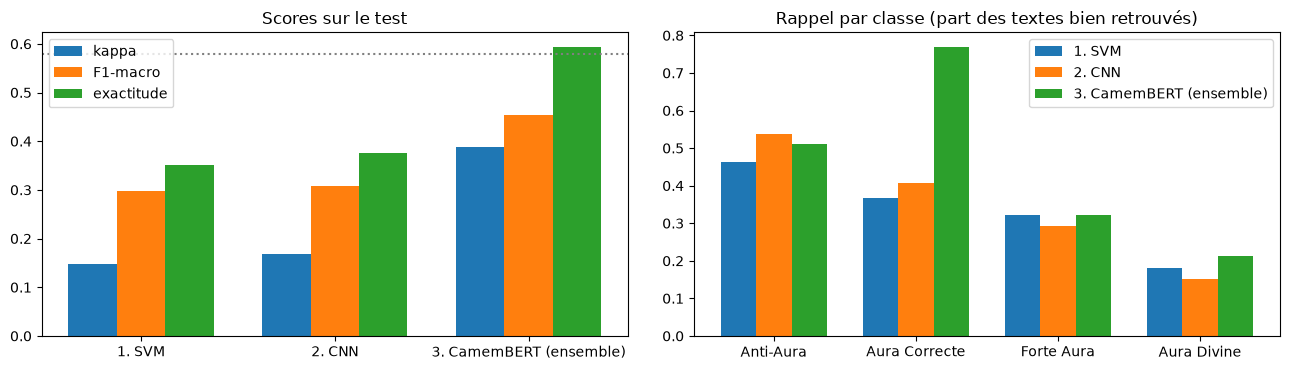

In [19]:
modeles = [n for n in RESULTATS if n[0].isdigit()]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
x = np.arange(3); larg = 0.25
for i, m in enumerate(["kappa", "F1-macro", "exactitude"]):
    ax[0].bar(x + (i - 1) * larg, [RESULTATS[n][m] for n in modeles], larg, label=m)
ax[0].set_xticks(x, modeles); ax[0].axhline(0.579, ls=":", c="gray"); ax[0].legend(); ax[0].set_title("Scores sur le test")
for i, n in enumerate(modeles):
    ax[1].bar(np.arange(4) + (i - 1) * larg, [RESULTATS[n][f"rappel {c}"] for c in COURT], larg, label=n)
ax[1].set_xticks(range(4), CLASSES); ax[1].legend(); ax[1].set_title("Rappel par classe (part des textes bien retrouvés)")
plt.tight_layout(); plt.show()

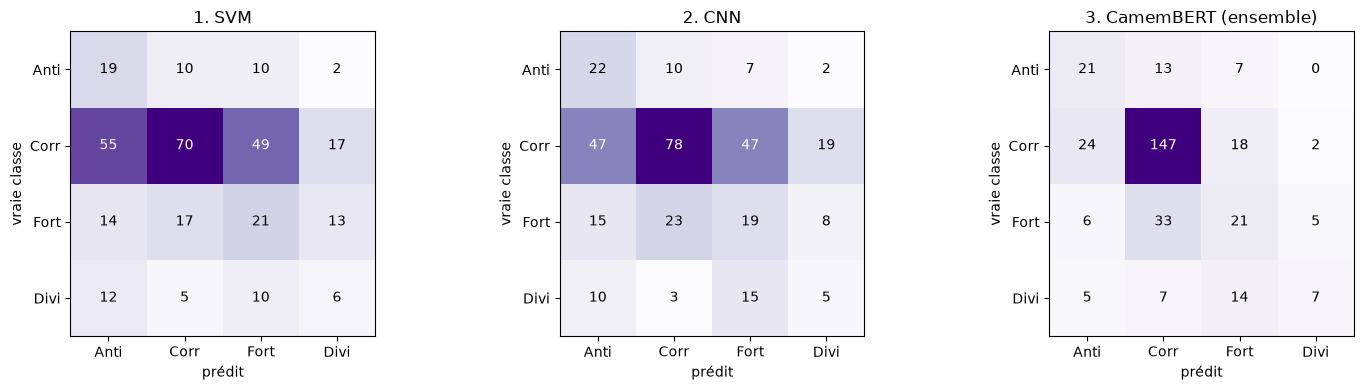

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, n in zip(ax, modeles):
    m = confusion_matrix(test["y"], PREDICTIONS[n], labels=range(4)); a.imshow(m, cmap="Purples")
    for i in range(4):
        for j in range(4): a.text(j, i, m[i, j], ha="center", va="center", color="white" if m[i, j] > m.max() / 2 else "black")
    a.set_xticks(range(4), COURT); a.set_yticks(range(4), COURT); a.set_xlabel("prédit"); a.set_ylabel("vraie classe"); a.set_title(n); a.grid(False)
plt.tight_layout(); plt.show()

In [21]:
# Exactitude par type de texte : où chaque modèle est-il bon ?
types = test["type"].values
par_type = pd.DataFrame({n: {t: np.mean(PREDICTIONS[n][types == t] == test["y"].values[types == t]) for t in pd.Series(types).value_counts().index[:9]} for n in modeles})
par_type.insert(0, "n", pd.Series(types).value_counts()[:9])
display(par_type.style.format({n: "{:.0%}" for n in modeles}))

,n,1. SVM,2. CNN,3. CamemBERT (ensemble)
discours,101,37%,33%,58%
interjection,65,37%,49%,86%
théâtre,35,17%,29%,31%
poésie,22,23%,18%,23%
question,20,35%,40%,85%
réponse,18,22%,17%,67%
roman,11,64%,73%,36%
prose,10,30%,10%,50%
texte officiel,9,44%,78%,67%


**Ce que nous retenons de la comparaison :**

| | Kappa validation | Kappa test | Exactitude test | Temps d'entraînement |
|---|---|---|---|---|
| SVM | 0,74 | 0,15 | 35 % | 2 secondes |
| CNN | 0,76 | 0,17 | 38 % | 10 secondes |
| CamemBERT (ensemble) | 0,95 | **0,39** | **59 %** | environ 50 minutes |

1. **CamemBERT gagne nettement**, avec un kappa plus de deux fois supérieur à celui des deux autres. C'est même le seul qui bat la stratégie « toujours Correcte » (58 %) en exactitude. Le pré-entraînement fait toute la différence : face à des textes d'un style nouveau, il s'appuie sur sa connaissance du français.

2. **Le SVM et le CNN sont proches.** Le CNN est un peu devant (0,17 contre 0,15), mais sur 330 textes un tel écart n'est pas assez grand pour affirmer qu'il est vraiment meilleur. Tous les deux trouvent trop rarement la classe « Correcte » (environ 40 % des textes Correcte retrouvés, contre 77 % pour CamemBERT). Comme ils ont appris sur un train équilibré, ils « voient » de l'aura un peu partout.

3. **Tous les modèles chutent entre la validation et le test**, surtout le SVM et le CNN (de 0,75 à environ 0,16). Notre validation, que nous avons écrite nous-mêmes dans le style du test, reste plus facile que de vrais textes. C'est la principale leçon du projet : une bonne note en validation ne garantit pas une bonne note en conditions réelles.

4. **Selon le type de texte**, CamemBERT est très bon sur les interjections et les questions de l'Assemblée (plus de 85 %) mais reste faible en théâtre et en poésie (moins d'un tiers). Les petits groupes, comme les romans (11 textes), sont trop petits pour en tirer une conclusion.

5. **La classe Divine reste difficile pour tous** (de 15 à 21 % retrouvés). Ce sont souvent des citations célèbres, dont l'aura vient aussi de leur réputation, que le modèle ne connaît pas.

6. **Il y a une limite à garder en tête.** Notre test a été annoté par une seule IA, et quand deux IA annotent les mêmes textes, elles ne s'accordent qu'à 0,61 de kappa. Même un modèle parfait ne pourrait pas dépasser beaucoup ce plafond.

## 9. Démo : les trois modèles sur les mêmes phrases

Pour finir, nous donnons les mêmes phrases aux trois modèles. Le nombre entre parenthèses est le score prédit par CamemBERT. Pour essayer vos propres phrases, il suffit de modifier `PHRASES_DEMO` dans la partie 1.

On voit bien la différence : pour le SVM et le CNN, « dab dab, six-seven » est une aura « Correcte », alors que c'est l'exemple type de l'Anti-Aura. CamemBERT, lui, le classe bien, et reconnaît la maxime sur le charisme comme une Forte Aura.

In [22]:
import transformers; transformers.logging.set_verbosity_error(); transformers.logging.disable_progress_bar()
from transformers import AutoTokenizer, AutoModelForSequenceClassification
CENTRES = np.array([-55, 7, 50, 87])   # score moyen de chaque classe, pour passer de probabilités à un score

def score_camembert(dossier, textes):
    tok = AutoTokenizer.from_pretrained(dossier); m = AutoModelForSequenceClassification.from_pretrained(dossier).to(DEVICE).eval()
    with torch.no_grad(): o = m(**tok(textes, padding=True, truncation=True, return_tensors="pt").to(DEVICE)).logits.cpu()
    return o.reshape(-1).numpy() * 100 if o.shape[1] == 1 else o.softmax(1).numpy() @ CENTRES

s_bert = sum(w * score_camembert(f"models/{n}/final", PHRASES_DEMO) for n, w in retenu["composants"].items() if n != "tfidf")
cnn_proba = cnn.charger("models/cnn", DEVICE)(PHRASES_DEMO)
pd.DataFrame({"phrase": PHRASES_DEMO,
              "SVM": [CLASSES[k] for k in svm.predict(PHRASES_DEMO)],
              "CNN": [CLASSES[k] for k in cnn_proba.argmax(1)],
              "CamemBERT": [f"{CLASSES[k]} ({s:+.0f})" for k, s in zip(np.digitize(s_bert, retenu["seuils"]), s_bert)]})

,phrase,SVM,CNN,CamemBERT
0,Je me suis chié dessus,Anti-Aura,Anti-Aura,Anti-Aura (-42)
1,"La bière c'est comme ma femme, brune et amer",Anti-Aura,Anti-Aura,Anti-Aura (-44)
2,fort en chocolat,Aura Correcte,Aura Correcte,Anti-Aura (-22)
3,"dab dab, six-seven",Aura Correcte,Aura Correcte,Anti-Aura (-43)
4,un accident de train a eu lieu en espagne ce s...,Aura Correcte,Aura Correcte,Aura Correcte (-4)
5,"En imposer pour ne pas avoir à imposer, voilà ...",Aura Divine,Aura Correcte,Forte Aura (+68)
6,"Loin des yeux, loin du cœur",Aura Correcte,Anti-Aura,Aura Correcte (-6)


## 10. Conclusion

**Le modèle que nous retenons est CamemBERT** (l'ensemble de la partie 7), et c'est lui qu'utilise notre WebApp. Il a le meilleur kappa, le meilleur F1 et la meilleure exactitude, et c'est le seul des trois qui comprend vraiment la langue. Son défaut est son coût : il lui faut un GPU pour s'entraîner et plusieurs centaines de millions de paramètres. Le SVM et le CNN restent disponibles dans la WebApp pour comparer.

**Ce que nous retenons du projet :**

1. **Le choix du modèle compte plus que ses réglages.** Chercher les hyperparamètres nous a fait gagner quelques centièmes de kappa. Passer d'un modèle appris de zéro à un modèle pré-entraîné a plus que doublé le score.
2. **Les données comptent autant que le modèle.** Nos plus gros progrès sont venus des textes écrits dans le style des vrais textes, plus que de n'importe quel réglage.
3. **La validation doit ressembler au vrai usage.** La nôtre était trop facile : elle nous a permis de classer les modèles entre eux, mais elle surestimait beaucoup leurs résultats réels.

**Pour aller plus loin :** faire annoter le test et une partie du train par des humains, constituer une validation avec de vrais textes plutôt que des textes écrits par nous, et ajouter davantage d'exemples de théâtre et de poésie, là où nos modèles sont les plus faibles.